## Exploração de Dados

### Passo 1: Ingestão e consolidação

Produzir uma base única, com a mesma estrutura para qualquer frequência de entrada. A frequência é parâmetro do pipeline, e não condição escrita no código: é ela que define a grade temporal, o tamanho das janelas móveis e o número de defasagens.


- Converter o timestamp para horário local ainda na ingestão e registrar o fuso
adotado.

- Consolidar em base longa, com chave de timestamp, tópico e grupo consumidor, e
reindexar cada par na grade completa, para que as falhas de coleta apareçam
como registros ausentes explícitos.

- Verificar a que nível cada métrica se refere, uma vez que métrica de tópico é
compartilhada por todos os grupos que o consomem e métrica de par não é. A
conclusão altera a interpretação de qualquer atributo que combine os dois sinais.

- Definir a política para valores ausentes de lag sem substituição por zero: ausência
de mensagens represadas e falha de coleta são informações distintas, e
confundi-las cria períodos artificiais de normalidade.

- Derivar a grade horária por agregação, explicitando a função adotada para cada
métrica.

\
**Conclusão do passo**: função de carga que recebe arquivo e frequência e devolve a
base consolidada, operando de forma idêntica nas três granularidades

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing

In [7]:
BASE_URL = 'https://raw.githubusercontent.com/AdaLimana/pos-ia/refs/heads/main/poc-02/'

In [10]:
df = pd.read_csv(BASE_URL + 'lag-e-throughput-5min.csv', sep=';', parse_dates=['timestamp'], index_col='timestamp')
print("Dados carregados com sucesso!")
print(f"Coletas: {df.shape[0]} registros")

df

Dados carregados com sucesso!
Coletas: 92165 registros


,throughput,lag,consumerGroup,topic
timestamp,,,,
2026-08-20 02:55:00+00:00,74.00,0.0,consumer-d,topic-a
2026-08-20 03:00:00+00:00,88.51,135.8,consumer-d,topic-a
2026-08-20 03:05:00+00:00,69.68,198.8,consumer-d,topic-a
2026-08-20 03:10:00+00:00,70.06,135.2,consumer-d,topic-a
2026-08-20 03:15:00+00:00,66.60,130.2,consumer-d,topic-a
...,...,...,...,...
2026-10-09 03:35:00+00:00,0.00,0.0,consumer-a,topic-c
2026-10-09 03:40:00+00:00,0.00,0.0,consumer-a,topic-c
2026-10-09 03:45:00+00:00,0.00,0.0,consumer-a,topic-c


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 92165 entries, 2026-08-20 02:55:00+00:00 to 2026-10-09 03:55:00+00:00
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   throughput     92165 non-null  float64
 1   lag            91954 non-null  float64
 2   consumerGroup  92165 non-null  object 
 3   topic          92165 non-null  object 
dtypes: float64(2), object(2)
memory usage: 3.5+ MB


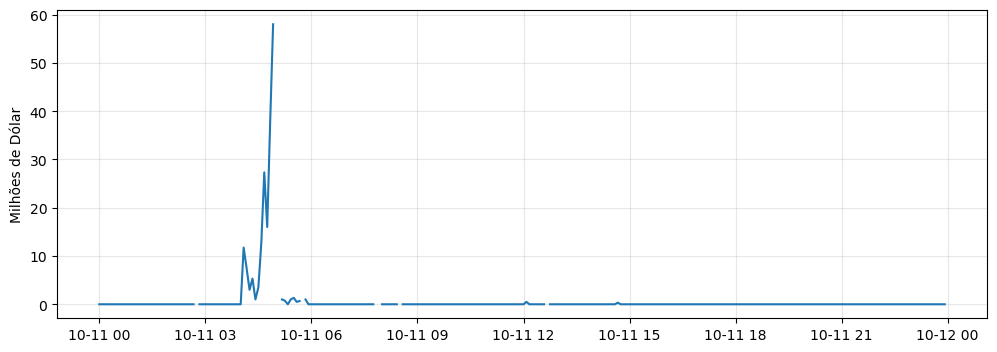

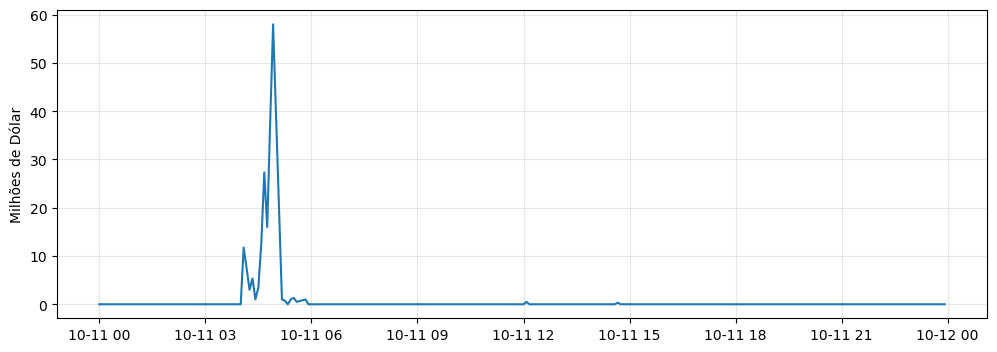

In [4]:
serie = df[(df['consumerGroup'] == 'consumer-b') & (df['topic'] == 'topic-c')].loc['2026-10-11']['lag']
# serie = df_1h[(df_1h['consumerGroup'] == 'consumer-a') & (df_1h['topic'] == 'topic-b')]['lag']

plt.figure(figsize=(12, 4))
plt.plot(serie.index, serie.values)
plt.title('')
plt.ylabel('Milhões de Dólar')
plt.grid(alpha=0.3)
plt.show()

serie = df[(df['consumerGroup'] == 'consumer-b') & (df['topic'] == 'topic-c')].loc['2026-10-11']['lag'].interpolate()

plt.figure(figsize=(12, 4))
plt.plot(serie.index, serie.values)
plt.title('')
plt.ylabel('Milhões de Dólar')
plt.grid(alpha=0.3)
plt.show()

### Passo 2: Auditoria de qualidade

Estabelecer o que será efetivamente modelado e verificar se a ingestão está correta.

- Perfilar cada par e granularidade: cobertura, duplicidades, lacunas, percentual de valores nulos e ausentes, distribuição e cauda das duas métricas.

- Comparar as fontes de granularidades distintas na janela em que se sobrepõem;
divergência indica diferença no procedimento de agregação da origem.

- Medir quanto da amplitude de um mesmo episódio sobrevive à agregação em cada
grade, o que constitui a justificativa quantitativa da granularidade adotada.

- Medir a correlação cruzada entre as duas métricas em diferentes defasagens, pois defasagem diferente de zero enfraquece a relação entre os sinais dentro de uma mesma janela agregada e orienta os atributos do passo 4.

- Avaliar a viabilidade de cada par, observando que séries predominantemente nulas ou de volumetria muito baixa podem não apresentar comportamento normal a ser aprendido, e submeter à empresa a proposta de quais integram a PoC.

\
**Conclusão do passo**: perfilamento fechado e recomendação de pares sustentada pelos números levantados.

### Passo 3: Análise exploratória

Caracterizar o comportamento normal de cada par e a forma dos episódios de interesse. Séries de cauda pesada exigem escala logarítmica e descrição por mediana, quantis e dispersão robusta; toda leitura de sazonalidade é feita em horário local.

- Visualizar as duas métricas sobrepostas no tempo, por par, com eixos
independentes. É a figura que torna visível o descolamento e que integra o relatório técnico.

- Caracterizar a sazonalidade por hora do dia e por dia da semana e avaliar em que medida ela compromete a adoção de um limiar único.

- Avaliar a autocorrelação para definir, por evidência, o número de defasagens do passo 4.

- Medir a correlação entre acúmulo e carga de entrada por método não paramétrico; correlação alta indica que o acúmulo é explicado pelo tráfego e que o sinal de interesse está no resíduo.

- Caracterizar os episódios candidatos quanto a duração, amplitude, comportamento simultâneo da carga de entrada e formato, e selecionar os de referência.

- Registrar eventuais trechos de deslocamento sustentado de patamar, que impõem
decisão específica no passo 7.

\
**Conclusão do passo**: caracterização que permite a um leitor externo entender como é o comportamento normal, como são os episódios de interesse e por que um limiar fixo não os distingue.

###Passo 4: Engenharia de atributos

Traduzir as duas métricas brutas em atributos que representem acúmulo descolado da carga de entrada e fora do padrão do par naquele horário. São calculados por par e com janelas expressas em unidades de tempo, e não em número de registros, para operar nas três granularidades.

- Normalizar a escala e, na hipótese de modelo consolidado, padronizar por par com medidas robustas, sem o que o par de maior volumetria domina o ajuste.

- Construir a relação entre as duas métricas, avaliando formulações alternativas
quanto à estabilidade nos períodos em que a carga de entrada se aproxima de
zero.

- Incluir as defasagens simples e cruzadas identificadas nos passos 2 e 3.

- Calcular estatísticas móveis em escala curta e longa, com medidas robustas,
incluindo a média móvel correspondente à regra vigente, necessária ao passo 6.

- Construir o desvio contra a baseline sazonal, que compara o valor observado com o histórico do mesmo par no mesmo horário e dia da semana. É a família que
incorpora contexto ao critério.

- Construir atributos de variação, com ao menos um sinal cruzado explícito, e de
tendência e persistência, que separam o pico transitório do acúmulo sustentado.

- Incluir atributos de calendário em horário local e reduzir o conjunto ao menor que preserva o desempenho.

\
**Conclusão do passo**: tabela de atributos documentada com nome, definição, janela e justificativa.

**Verificação de vazamento**. Antes de avançar, confirmar que todas as janelas são retrospectivas; que estatísticas, baselines sazonais e parâmetros de normalização usam apenas histórico anterior ao ponto avaliado e são ajustados somente no treino; e que os registros iniciais de cada par, sem histórico suficiente, são descartados. O teste prático é recalcular os atributos de um ponto usando apenas os dados até aquele instante e comparar com o valor registrado; divergência indica vazamento.

##Modelagem e Desenvolvimento

###Passo 5: Protocolo de avaliação

Definir o protocolo antes de treinar o primeiro modelo; estabelecido depois, deixa de ser critério e passa a ser justificativa. A separação é feita em blocos contíguos e cronológicos, pois a divisão aleatória permite que o modelo acerte o teste por proximidade temporal.

- Implementar o backtest com origem móvel, nas variantes de janela expansiva e
deslizante.

- Posicionar os cortes de modo que ao menos um episódio de referência recaia no
período de teste; corte que mantenha todos no treino impede a medição de
sensibilidade.

-Declarar como limitação do ciclo a granularidade cujo período não contenha
episódio de referência.

- Definir a política de contaminação do treino e testar ao menos duas alternativas entre remoção do episódio, manutenção e métodos robustos, reportando a diferença.

\
**Conclusão do passo**: protocolo escrito, com cortes justificados, e função de avaliação pronta para receber qualquer modelo.


###Passo 6: Modelos de referência

Estabelecer o patamar contra o qual a PoC é medida, antes de qualquer modelo de
detecção. O escopo mede o mérito da PoC pela redução dos acionamentos indevidos
sem perda dos legítimos, o que torna esses modelos condição para a existência de
resultado.

- Reproduzir a regra vigente sobre as mesmas coletas que alimentam os demais
modelos, observando que um mesmo número de coletas corresponde a intervalos
distintos em cada grade.

- Solicitar à empresa o limiar configurado por tópico e, enquanto não for
disponibilizado, varrer a faixa e produzir a curva de acionamentos por período da regra vigente.

- Implementar o modelo de calendário puro, sem a métrica de carga de entrada.
Modelo de detecção que não supere essa referência indica ganho de sazonalidade,
e não de aprendizado, resultado que deve ser reportado.

- Implementar o limiar robusto por par, que mede o ganho obtido apenas por
abandonar o valor único global.

\
**Conclusão do passo**: os três modelos de referência avaliados pelo protocolo e
registrados na tabela comparativa.

###Passo 7: Modelos de detecção não supervisionada

Produzir um score de anomalia por coleta e convertê-lo em decisão de alerta. A ordem é crescente de custo e cada modelo só é iniciado após a medição do anterior, de modo que o ganho possa ser atribuído a uma decisão específica.

- Decomposição sazonal com limiar robusto sobre o resíduo, reajustada a cada
origem do backtest para que o ajuste não utilize períodos posteriores.

- Resíduo de regressão do acúmulo em função da carga de entrada e do contexto
temporal, que é a tradução mais direta da tese do escopo e produz explicação
acionável pelo analista, na forma de valor esperado contra valor observado.

- Isolation Forest sobre os atributos do passo 4, observando que o método não
incorpora noção temporal, que a mistura de pares exige padronização de escala e
que o parâmetro de contaminação determina o volume de acionamentos, devendo
ser reportado como curva.

- Comparar a estratégia de um modelo por par com a de modelo único com tópico e
grupo consumidor como contexto, registrando desempenho e implicação
operacional.

- Ajustar hiperparâmetros sobre a validação, nunca sobre o teste, com registro dasconfigurações avaliadas.

- Aplicar o pós-processamento, que converte score em alerta e responde por parte
significativa da redução de acionamentos indevidos: persistência mínima, histerese entre abertura e encerramento, supressão temporária de novos alertas do mesmo par e consolidação das coletas sinalizadas em evento único.

- Definir o tratamento dos deslocamentos sustentados de patamar, caso identificados no passo 3: baseline de adaptação rápida os incorpora como normal e silencia, baseline rígida sinaliza por dias consecutivos, e nenhum dos dois comportamentos é adequado.

\
**Conclusão do passo**: tabela comparativa com modelos de referência e de detecção, avaliados pelo mesmo protocolo, com a configuração de pós-processamento explicitada por linha. Concluído este passo, a PoC ingressa na fase de Validação do Projeto.